# Campus Café: From Messy Data to Business Decisions
## A six-hour introduction to business analytics with Python

**Audience:** college students who know basic Python, pandas, and simple graphs. No prior regression is assumed.

**Your role:** junior analyst for Campus Café, a fictional business with two locations: Library and Student Center.
The manager wants to understand daily demand, discounts, and operating performance, then try a simple demand model.
You will turn an imperfect daily export into evidence for three business recommendations.

**Data:** entirely synthetic, created for this assignment. These are fictional 2025 records, not real campus or customer data.
One legitimate row represents **one location on one day**. Both locations are open every day in this simplified case.
The raw file has 742 rows, including intentionally duplicated records. No web access, API key, or yfinance is needed.

### Schedule: 360 minutes of active work

| Part | Activities | Time |
|---|---|---:|
| 1. Data preparation | 1–6, 20 minutes each | 120 minutes |
| 2. Exploratory analytics | 7–12, 30 minutes each | 180 minutes |
| 3. Linear regression | 13–16, 15 minutes each | 60 minutes |
| **Total** | Reading, running code, exercises, writing | **360 minutes** |

Time estimates include the readings and exercises, not just running the supplied code. Breaks and software installation are outside the six hours.
Work in order; every activity has a reading, a worked example, and independent work. Optional challenges are outside the six hours.

### What to submit

1. This notebook, renamed `LastName_FirstName_Cafe.ipynb`, with exercise code, written answers, and visible outputs.
2. The `campus_cafe_clean.csv` file you export in Activity 6.
3. Your 250–350-word manager recommendation in Activity 12 and model evaluation in Activity 16 (inside this notebook).

Before submitting, restart the kernel and run all cells. Resolve errors and confirm your answers still match the results.
The supplied starter notebook runs, but **running it unchanged does not complete the exercises**.
Mark assumptions clearly. If you use an AI assistant, follow your instructor's policy and document the help received.

**Suggested grading (100 points):** preparation 30; exploration and recommendation 45; regression 20; reproducibility and clarity 5.
Points reward accurate analysis, supported reasoning, and clear explanations, as well as working code.

## Before the clock starts: open the files

Put this notebook and `campus_cafe_raw.csv` in the **same folder**. Open the notebook in JupyterLab, VS Code, or Google Colab.
In Colab, upload the CSV using the Files panel after opening the notebook. Re-upload it after a runtime reset if necessary.
The CSV must be in the notebook's working directory; the next cell prints that directory and checks for the file.

Use Python 3.10 or newer with `pandas`, `numpy`, `matplotlib`, and `scikit-learn` installed.
In Jupyter/Colab, if an import fails, run the following in a temporary code cell, then restart the kernel:

```python
%pip install pandas numpy matplotlib scikit-learn
```

Run code cells with **Shift+Enter**. Double-click a written-response cell to edit it, then Shift+Enter to display it.
`display()` shows a table, `head()` shows its first rows, and `#` starts a Python comment.
Keep the raw CSV unchanged. All cleaning happens in a copy.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
DATA_PATH = Path('campus_cafe_raw.csv')
print('Working folder:', Path.cwd())
if not DATA_PATH.exists():
    raise FileNotFoundError('Put campus_cafe_raw.csv in the working folder shown above, then rerun.')

Working folder: C:\Users\Administrator\Documents\Codex\2026-10-31\files-mentioned-by-the-user-campus\work\revised


## Data dictionary and case assumptions

All money is in **US dollars**. All values describe the whole location-day, not a single transaction.

| Column | Meaning | Valid interpretation |
|---|---|---|
| `record_id` | Export identifier | Unique for a legitimate record; repeated in accidental copies |
| `date` | Trading date | YYYY-MM-DD, during 2025 |
| `location` | Café location | Library or Student Center |
| `transactions` | Number of purchases that day | Positive whole number |
| `avg_ticket` | Average purchase amount **before discounts** | Positive dollars per transaction |
| `discount_rate` | Average effective discount across the day's purchases | Fraction: 0.10 means 10%; case values are 0, 0.10, 0.20 |
| `food_share` | Fraction of pre-discount sales from food | Fraction between 0 and 1; remaining sales are beverages |
| `temperature_f` | Observed daily average outdoor temperature | Degrees Fahrenheit; missing on some days |
| `rainfall_mm` | Observed daily rainfall | Millimeters; 0 means recorded no rain, blank means unknown |
| `campus_event` | Whether an event took place on campus | Yes or No; applies to both locations |
| `staff_hours` | Total paid employee-hours | E.g., two people working eight hours each = 16 employee-hours |
| `waste_cost` | Additional ingredient cost of discarded stock | Nonnegative dollars; excludes ingredients in sold products |

**Accounting assumptions for this exercise:** food ingredient cost is 48% of food's pre-discount sales;
beverage ingredient cost is 32% of beverage pre-discount sales. Labor costs $18 per employee-hour.
Discounts reduce revenue but do not reduce ingredient cost. Waste is separate from ingredient costs for sold goods.
Ignore taxes, tips, rent, utilities, payroll taxes, and other fixed or omitted expenses.

You will calculate:

- `gross_sales = transactions × avg_ticket` (before discounts).
- `net_revenue = gross_sales × (1 − discount_rate)`.
- `ingredient_cost = gross_sales × [0.48 × food_share + 0.32 × (1 − food_share)]`.
- `gross_profit = net_revenue − ingredient_cost` (before labor and waste).
- `contribution = gross_profit − labor_cost − waste_cost`.

Contribution is an exercise-specific operating measure; it is **not net profit**.
These percentages and wage are invented case assumptions, not researched industry benchmarks.

# Part 1 — Data preparation · 120 minutes
## Activity 1 — Understand the export · 20 minutes
**Budget:** read 5 min; run/inspect 5 min; exercise/write 10 min.

Before cleaning data, identify its *grain*: what does one row represent? Two cafés can have the same date without being duplicates.
Counting rows is different from counting days, and summing both locations answers a different question from describing a typical location-day.
Pandas infers data types when it reads a CSV; inference is useful but does not guarantee correct meaning.
A date can initially be text, and a numeric column can contain a value that is mathematically valid but impossible in the business.

The example loads the raw file, preserves it, and prints an initial profile. `info()` reports data types and nonmissing counts;
`describe()` summarizes numeric values. Do not clean anything yet.

In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
display(raw.head())
print('Rows and columns:', raw.shape)
raw.info()
display(raw.describe())

,record_id,date,location,transactions,avg_ticket,discount_rate,food_share,temperature_f,rainfall_mm,campus_event,staff_hours,waste_cost
0,D0326,2025-06-12,Student Center,197,9.16,0.0,0.380,72.9,0.0,No,20.6,26.75
1,D0462,2025-08-19,Student Center,251,9.09,0.2,0.351,82.6,0.0,No,28.3,36.82
2,D0376,2025-07-07,Student Center,183,8.08,0.0,0.391,79.8,0.0,No,17.7,26.06
3,D0468,2025-08-22,STUDENT CENTER,173,6.89,0.0,0.489,70.1,0.0,No,19.7,28.01
4,D0596,2025-10-25,Student Center,155,8.17,0.0,0.438,55.6,0.0,No,20.4,25.24


Rows and columns: (742, 12)
<class 'pandas.DataFrame'>
RangeIndex: 742 entries, 0 to 741
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   record_id      742 non-null    str    
 1   date           742 non-null    str    
 2   location       742 non-null    str    
 3   transactions   742 non-null    int64  
 4   avg_ticket     742 non-null    float64
 5   discount_rate  742 non-null    float64
 6   food_share     742 non-null    float64
 7   temperature_f  724 non-null    float64
 8   rainfall_mm    730 non-null    float64
 9   campus_event   742 non-null    str    
 10  staff_hours    728 non-null    float64
 11  waste_cost     742 non-null    float64
dtypes: float64(7), int64(1), str(4)
memory usage: 69.7 KB


,transactions,avg_ticket,discount_rate,food_share,temperature_f,rainfall_mm,staff_hours,waste_cost
count,742.000000,742.000000,742.000000,742.000000,724.000000,730.000000,728.000000,742.000000
mean,146.475741,7.699313,0.097439,0.363581,56.828591,1.637397,16.685027,20.522776
std,45.135769,0.951059,1.037674,0.111785,17.220118,3.133383,4.633852,8.010623
min,-10.000000,-2.000000,0.000000,0.132000,17.700000,0.000000,10.000000,1.390000
25%,117.000000,7.212500,0.000000,0.279250,41.300000,0.000000,13.000000,13.705000
50%,148.000000,7.730000,0.000000,0.366000,56.800000,0.000000,16.650000,20.390000
75%,179.000000,8.240000,0.100000,0.443000,73.025000,2.500000,20.100000,27.152500
max,264.000000,9.760000,20.000000,1.500000,89.400000,21.000000,32.300000,40.660000


### Exercise 1 — Establish the grain


Print the number of distinct raw location labels and their counts, the number of distinct record IDs,
and the number of missing values in each column. In 3–5 sentences:
(a) define a row, (b) explain why 742 rows do not mean 742 trading days, and
(c) identify three issues worth investigating. Cite actual counts from your outputs.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [3]:
# Exercise 1: Establish the grain
print("=== Location value counts (including NaN) ===")
print(raw['location'].value_counts(dropna=False))

print(f"\nDistinct location labels: {raw['location'].nunique()}")
print(f"Distinct record IDs: {raw['record_id'].nunique()}")

print("\n=== Missing values per column ===")
print(raw.isna().sum())

=== Location value counts (including NaN) ===
location
Student Center    357
Library           355
STUDENT CENTER     15
 library           15
Name: count, dtype: int64

Distinct location labels: 4
Distinct record IDs: 730

=== Missing values per column ===
record_id         0
date              0
location          0
transactions      0
avg_ticket        0
discount_rate     0
food_share        0
temperature_f    18
rainfall_mm      12
campus_event      0
staff_hours      14
waste_cost        0
dtype: int64


**Your response:**

Each row should represent one café on one date, rather than one customer or one transaction. The raw file has 742 rows and 730 distinct record IDs, including 12 duplicate copies, and the two locations can have records on the same date. I found four location labels even though there are only two cafés, so the labels need cleaning. There are also 18 missing temperatures, 12 missing rainfall values, and 14 missing staff-hour values. Negative transactions and discounts entered as 20 instead of 0.20 are other problems to check.

## Activity 2 — Standardize labels and dates · 20 minutes
**Budget:** read 5 min; worked example 5 min; exercise/write 10 min.

`'Library'`, `' library '`, and `'LIBRARY'` can mean the same location but pandas treats them as different strings.
`str.strip()` removes outer spaces; `str.lower()` makes case consistent; `map()` applies an explicit dictionary of accepted labels.
An unmapped label becomes missing, which is easier to detect than silently accepting a new category.

`pd.to_datetime(..., errors='coerce')` converts invalid date strings to `NaT` (missing dates).
Coercion is a detection method, not a repair: we cannot reconstruct an unknown date from this export.
The following **provided pipeline cells** establish the shared dataset used later. Exercises extend or audit them;
you do not have to fill an earlier TODO to make a later activity run.

In [4]:
df['location'] = (df['location'].str.strip().str.lower()
                  .map({'library': 'Library', 'student center': 'Student Center'}))
df['campus_event'] = df['campus_event'].str.strip().str.lower().map({'yes': 1, 'no': 0})
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d', errors='coerce')
display(df[['date', 'location', 'campus_event']].head())

,date,location,campus_event
0,2025-06-12,Student Center,0
1,2025-08-19,Student Center,0
2,2025-07-07,Student Center,0
3,2025-08-22,Student Center,0
4,2025-10-25,Student Center,0


### Exercise 2 — Verify the conversions


Create a table of rows whose converted date is missing, showing record ID, location, and date.
Print the unique cleaned location and event values. Explain why inventing dates would be risky and
why a missing event value must not automatically become 0.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [5]:
# Exercise 2: Verify conversions
missing_date_rows = df.loc[df['date'].isna(), ['record_id', 'location', 'date']]
print("Rows with missing (unparseable) dates:")
display(missing_date_rows)

print("\nUnique cleaned locations:", df['location'].unique())
print("Unique cleaned event values:", df['campus_event'].unique())
print("Rows with NaN location:", df['location'].isna().sum())
print("Rows with NaN campus_event:", df['campus_event'].isna().sum())

Rows with missing (unparseable) dates:


,record_id,location,date
333,D0305,Library,NaT
735,D0674,Student Center,NaT



Unique cleaned locations: <StringArray>
['Student Center', 'Library']
Length: 2, dtype: str
Unique cleaned event values: [0 1]
Rows with NaN location: 0
Rows with NaN campus_event: 0


**Your response:**

The dates for D0305 and D0674 could not be converted. I would not guess their dates because that could put their sales in the wrong month or weekday, or even on the wrong side of the model's training/test split. The cleaned location values are Library and Student Center, and the event values are 0 and 1, with no missing values in either field. If an event value were missing, I would keep it unknown rather than change it to 0, because unknown does not mean that no event happened.

## Activity 3 — Remove duplicates and detect invalid values · 20 minutes
**Budget:** read 5 min; worked example 5 min; exercise/write 10 min.

An exact duplicate is a repeated export record. A business-key duplicate is a repeated location-date pair;
it could be an accidental copy or two conflicting versions. Do not delete conflicting records without a policy.
Here the case tells us accidental copies are exact, so removing exact duplicates is justified.

Next apply domain rules. A discount of 20 means 2,000%, not 20%; although we suspect a percent-entry error,
we have no verified correction, so flag the row. Large sales on an event day may be real and should not be deleted
merely for being unusual. Validation uses business meaning, not a rule that all extremes are errors.

In [6]:
before_dedup = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = before_dedup - len(df)
print('Exact duplicates removed:', duplicates_removed)
print('Remaining duplicate record IDs:', df['record_id'].duplicated().sum())

valid = pd.DataFrame({
    'date_ok': df['date'].notna() & df['date'].between('2025-01-01', '2025-12-31'),
    'location_ok': df['location'].isin(['Library', 'Student Center']),
    'event_ok': df['campus_event'].isin([0, 1]),
    'transactions_ok': df['transactions'].gt(0) & df['transactions'].mod(1).eq(0),
    'ticket_ok': df['avg_ticket'].gt(0),
    'discount_ok': df['discount_rate'].isin([0, .10, .20]),
    'food_share_ok': df['food_share'].between(0, 1),
    'rain_ok': df['rainfall_mm'].isna() | df['rainfall_mm'].ge(0),
    'staff_ok': df['staff_hours'].isna() | df['staff_hours'].gt(0),
    'waste_ok': df['waste_cost'].ge(0)
})
display((~valid).sum().rename('failed_rule_count'))
invalid_rows = df.loc[~valid.all(axis=1)].copy()

Exact duplicates removed: 12
Remaining duplicate record IDs: 0


date_ok            2
location_ok        0
event_ok           0
transactions_ok    4
ticket_ok          3
discount_ok        2
food_share_ok      2
rain_ok            0
staff_ok           0
waste_ok           0
Name: failed_rule_count, dtype: int64

### Exercise 3 — Build an audit trail


Display the invalid records with their ID, date, transactions, ticket, discount, and food share.
Calculate how many rows fail **at least one** rule. Why can adding failure counts across columns
overcount invalid rows in other datasets? Explain why a date-only duplicate check would be wrong here.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [7]:
# Exercise 3: Build an audit trail
print("Invalid records:")
display(invalid_rows[['record_id', 'date', 'transactions', 'avg_ticket', 'discount_rate', 'food_share']])
print(f"\nRows failing at least one rule: {len(invalid_rows)}")
print(f"Sum of per-column failure counts: {(~valid).sum().sum()}")
print(f"Difference (overcount): {(~valid).sum().sum() - len(invalid_rows)}")

Invalid records:


,record_id,date,transactions,avg_ticket,discount_rate,food_share
57,D0180,2025-03-31,120,-2.00,0.0,0.354
147,D0248,2025-05-04,-10,7.70,0.0,0.429
249,D0594,2025-10-24,-10,8.95,0.0,0.435
258,D0572,2025-10-13,174,-2.00,0.0,0.458
287,D0140,2025-03-11,144,-2.00,0.0,0.406
333,D0305,NaT,85,7.75,0.0,0.276
357,D0602,2025-10-28,-10,7.63,0.0,0.464
380,D0459,2025-08-18,120,6.51,0.0,1.500
383,D0176,2025-03-29,143,8.32,20.0,0.515
418,D0418,2025-07-28,-10,7.32,0.0,0.415



Rows failing at least one rule: 13
Sum of per-column failure counts: 13
Difference (overcount): 0


**Your response:**

There are 13 invalid records: four have negative transactions, three have negative ticket values, two have invalid discounts, two have food shares above 1, and two have missing dates. The rule-failure counts also add up to 13, so no row in this file fails more than one rule. In another dataset, adding these counts could count a row twice if it had two different problems. Checking whether each row fails any rule avoids this problem. Checking duplicates by date alone would be wrong because Library and Student Center can both have a valid record on the same day. A repeated date/location pair needs checking for conflicting records before deletion; here the case allows removal of exact copies.

## Activity 4 — Make missing-data decisions · 20 minutes
**Budget:** read 5 min; worked example 5 min; exercise/write 10 min.

Missing is not the same as zero. A blank rainfall value does not establish dry weather, and a blank staff-hours value
does not mean no employees worked. Dropping every row with any missing field can discard useful sales observations.
For this case, we remove invalid core records because we cannot verify their corrections. We keep missing weather values.
Plots that require weather will use only rows with observed weather, and we will report the sample size.

For staffing, we preserve the reported value and create an **estimate** using the median for the same location.
The median is less influenced by unusually busy days than the mean. Keep an imputation flag so users can identify estimates.
Imputation can hide variability and change profitability rankings; it is an assumption, not recovered truth.
This staffing estimate is for descriptive accounting only. The regression will handle missing predictor values using training data alone.

In [8]:
clean = df.loc[valid.all(axis=1)].copy()
clean['staff_hours_imputed'] = clean['staff_hours'].isna()
location_median = clean.groupby('location')['staff_hours'].transform('median')
clean['staff_hours_used'] = clean['staff_hours'].fillna(location_median)
print('Rows retained:', len(clean))
display(clean[['temperature_f', 'rainfall_mm', 'staff_hours', 'staff_hours_used']].isna().sum())

Rows retained: 717


temperature_f       18
rainfall_mm         12
staff_hours         14
staff_hours_used     0
dtype: int64

### Exercise 4 — Compare two staffing policies


For each location, calculate observed mean and median staff hours and the number of imputed rows.
Create `staff_hours_mean` in a separate temporary table by filling missing values with the location mean.
Compare the **total labor cost on imputed rows only** under the mean and median policies at $18/hour.
Report the difference in dollars, identify which fields remain missing, and explain one limitation of either policy.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [9]:
# Exercise 4: Compare staffing policies
print("=== Per-location staffing summary ===")
for loc in ['Library', 'Student Center']:
    subset = clean.loc[clean['location'] == loc]
    observed = subset.loc[subset['staff_hours'].notna(), 'staff_hours']
    n_imputed = int(subset['staff_hours_imputed'].sum())
    print(f"\n{loc}:")
    print(f"  Observed mean:   {observed.mean():.2f} hours")
    print(f"  Observed median: {observed.median():.2f} hours")
    print(f"  Imputed rows:    {n_imputed}")

# Mean-based imputation (separate temporary column, does NOT modify clean)
temp_compare = clean.copy()
location_mean_fill = clean.groupby('location')['staff_hours'].transform('mean')
temp_compare['staff_hours_mean'] = temp_compare['staff_hours'].fillna(location_mean_fill)

imputed_mask = temp_compare['staff_hours_imputed']
median_labor_imputed = (temp_compare.loc[imputed_mask, 'staff_hours_used'] * 18).sum()
mean_labor_imputed = (temp_compare.loc[imputed_mask, 'staff_hours_mean'] * 18).sum()

print(f"\n=== Labor cost comparison (imputed rows only) ===")
print(f"Median policy total labor cost: ${median_labor_imputed:.2f}")
print(f"Mean policy total labor cost:   ${mean_labor_imputed:.2f}")
print(f"Difference (mean − median):     ${mean_labor_imputed - median_labor_imputed:.2f}")

print(f"\n=== Fields still missing after imputation ===")
print(clean[['temperature_f', 'rainfall_mm', 'staff_hours']].isna().sum())

=== Per-location staffing summary ===

Library:
  Observed mean:   14.26 hours
  Observed median: 13.70 hours
  Imputed rows:    8

Student Center:
  Observed mean:   19.11 hours
  Observed median: 19.10 hours
  Imputed rows:    6

=== Labor cost comparison (imputed rows only) ===
Median policy total labor cost: $4035.60
Mean policy total labor cost:   $4117.59
Difference (mean − median):     $81.99

=== Fields still missing after imputation ===
temperature_f    18
rainfall_mm      12
staff_hours      14
dtype: int64


**Your response:**

Library's observed mean is 14.26 employee-hours and its median is 13.70, with eight missing values filled. Student Center's mean is 19.11 and its median is 19.10, with six filled values. For these 14 rows only, labor cost is $4,117.59 with the mean policy and $4,035.60 with the median policy, a difference of $81.99. Temperature still has 18 missing values and rainfall has 12; the original staff_hours column keeps its 14 blanks, while staff_hours_used has none. A limitation is that both policies use the same estimate for every missing day at a location, even though staffing may differ on weekends or event days.

## Activity 5 — Create business measures · 20 minutes
**Budget:** read 5 min; worked example 5 min; exercise/write 10 min.

Revenue is money from customers; it does not account for the cost of producing sales.
Gross margin is gross profit divided by net revenue. A margin of 0.60 means 60 cents of gross profit per revenue dollar.
We compute ingredient cost from **pre-discount** sales because a discount does not make the ingredients cheaper.

A daily margin is a ratio. To calculate a margin across multiple days, divide total gross profit by total net revenue.
Taking a simple average of daily margins gives a quiet day the same weight as a busy day.
Use total employee-hours, not opening hours, when calculating labor cost.

In [10]:
FOOD_COST_RATE = .48
BEVERAGE_COST_RATE = .32
HOURLY_LABOR_COST = 18.0
clean['gross_sales'] = clean['transactions'] * clean['avg_ticket']
clean['net_revenue'] = clean['gross_sales'] * (1 - clean['discount_rate'])
clean['ingredient_cost'] = clean['gross_sales'] * (
    FOOD_COST_RATE * clean['food_share'] + BEVERAGE_COST_RATE * (1-clean['food_share']))
clean['gross_profit'] = clean['net_revenue'] - clean['ingredient_cost']
clean['gross_margin'] = clean['gross_profit'] / clean['net_revenue']
clean['labor_cost'] = HOURLY_LABOR_COST * clean['staff_hours_used']
clean['contribution'] = clean['gross_profit'] - clean['labor_cost'] - clean['waste_cost']
clean['weekday'] = clean['date'].dt.day_name()
clean['month'] = clean['date'].dt.month
clean['is_weekend'] = clean['date'].dt.dayofweek >= 5
display(clean[['record_id','net_revenue','gross_profit','labor_cost','contribution']].head().round(2))

,record_id,net_revenue,gross_profit,labor_cost,contribution
0,D0326,1804.52,1117.36,370.8,719.81
1,D0462,1825.27,967.03,509.4,420.81
2,D0376,1478.64,912.97,318.6,568.31
3,D0468,1191.97,717.28,354.6,334.67
4,D0596,1266.35,772.37,367.2,379.93


### Exercise 5 — Reconcile one day


Choose one retained row with a 20% discount. Using its displayed inputs, independently calculate net revenue,
ingredient cost, gross profit, labor cost, and contribution. Compare your values with the calculated columns
(allow tiny floating-point rounding differences). Explain why `gross_sales × (1 − food_share) × 0.32`
is only part of ingredient cost, and why contribution cannot be labeled net profit.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [11]:
# Exercise 5: Reconcile one day
# Select one row with 20% discount
row = clean.loc[clean['discount_rate'] == 0.20].iloc[0]
print(f"Selected: {row['record_id']}, date={row['date'].date()}, location={row['location']}")
print(f"transactions={row['transactions']}, avg_ticket=${row['avg_ticket']:.2f}, "
      f"discount_rate={row['discount_rate']}, food_share={row['food_share']:.3f}")
print(f"staff_hours_used={row['staff_hours_used']:.1f}, waste_cost=${row['waste_cost']:.2f}")

# Independent calculation
gs = row['transactions'] * row['avg_ticket']
nr = gs * (1 - row['discount_rate'])
ic = gs * (FOOD_COST_RATE * row['food_share'] + BEVERAGE_COST_RATE * (1 - row['food_share']))
gp = nr - ic
lc = HOURLY_LABOR_COST * row['staff_hours_used']
ct = gp - lc - row['waste_cost']

print(f"\n=== Independent calculation ===")
print(f"gross_sales      = {row['transactions']} × {row['avg_ticket']:.2f} = ${gs:.2f}")
print(f"net_revenue      = {gs:.2f} × (1 − {row['discount_rate']}) = ${nr:.2f}")
print(f"ingredient_cost  = {gs:.2f} × (0.48×{row['food_share']:.3f} + 0.32×{1-row['food_share']:.3f}) = ${ic:.2f}")
print(f"gross_profit     = ${nr:.2f} − ${ic:.2f} = ${gp:.2f}")
print(f"labor_cost       = 18 × {row['staff_hours_used']:.1f} = ${lc:.2f}")
print(f"contribution     = ${gp:.2f} − ${lc:.2f} − ${row['waste_cost']:.2f} = ${ct:.2f}")

print(f"\n=== Comparison with DataFrame columns ===")
print(f"DataFrame net_revenue  = ${row['net_revenue']:.2f}  (match: {abs(nr - row['net_revenue']) < 0.01})")
print(f"DataFrame gross_profit = ${row['gross_profit']:.2f}  (match: {abs(gp - row['gross_profit']) < 0.01})")
print(f"DataFrame contribution = ${row['contribution']:.2f}  (match: {abs(ct - row['contribution']) < 0.01})")
checks = {"net_revenue": nr, "ingredient_cost": ic, "gross_profit": gp, "labor_cost": lc, "contribution": ct}
for measure, value in checks.items():
    assert np.isclose(value, row[measure]), measure
print("All five accounting measures match.")

Selected: D0462, date=2025-08-19, location=Student Center
transactions=251, avg_ticket=$9.09, discount_rate=0.2, food_share=0.351
staff_hours_used=28.3, waste_cost=$36.82

=== Independent calculation ===
gross_sales      = 251 × 9.09 = $2281.59
net_revenue      = 2281.59 × (1 − 0.2) = $1825.27
ingredient_cost  = 2281.59 × (0.48×0.351 + 0.32×0.649) = $858.24
gross_profit     = $1825.27 − $858.24 = $967.03
labor_cost       = 18 × 28.3 = $509.40
contribution     = $967.03 − $509.40 − $36.82 = $420.81

=== Comparison with DataFrame columns ===
DataFrame net_revenue  = $1825.27  (match: True)
DataFrame gross_profit = $967.03  (match: True)
DataFrame contribution = $420.81  (match: True)
All five accounting measures match.


**Your response:**

For D0462 at Student Center on August 19, there are 251 transactions, a $9.09 ticket, a 20% discount, food share of 0.351, 28.3 employee-hours, and $36.82 in waste.

| Measure | Calculation | Result |
|---|---|---|
| Gross sales | 251 × 9.09 | $2,281.59 |
| Net revenue | 2,281.59 × 0.80 | $1,825.27 |
| Ingredient cost | 2,281.59 × (0.48 × 0.351 + 0.32 × 0.649) | $858.24 |
| Gross profit | Net revenue − ingredient cost | $967.03 |
| Labor cost | 28.3 × 18 | $509.40 |
| Contribution | Gross profit − labor cost − 36.82 | $420.81 |

These results match the calculated columns; the code uses full precision before rounding for display. The expression using only (1 − food_share) and 0.32 covers beverages, so it leaves out food ingredient costs. Contribution is not net profit because expenses such as rent, utilities, and taxes have not been deducted.

## Activity 6 — Check, document, and export · 20 minutes
**Budget:** read 4 min; checks 6 min; exercise/write/export 10 min.

Cleaning is complete only when you can explain what changed and verify the resulting grain.
An assertion is a condition that must be true. If a check fails, inspect the offending records;
do not remove the check to make the notebook run. Exact equality is appropriate for row counts;
`np.allclose()` is useful for arithmetic involving decimals.

Sorting gives predictable output. Export without the pandas index, which is not part of the business data.
The row-count ledger below separates copies from invalid records and avoids describing both as ordinary missing data.
These expected counts apply only to the original, unchanged assignment CSV.

In [12]:
clean = clean.sort_values(['date','location']).reset_index(drop=True)
audit = pd.Series({'raw_rows':len(raw), 'exact_duplicates_removed':duplicates_removed,
    'invalid_unique_rows_removed':len(invalid_rows), 'retained_rows':len(clean),
    'staff_hours_imputed':int(clean['staff_hours_imputed'].sum())})
display(audit)
assert len(raw) - duplicates_removed - len(invalid_rows) == len(clean)
assert len(clean) == 717, 'Recheck the cleaning pipeline using the original CSV.'
assert not clean.duplicated(['date','location']).any()
assert not clean['record_id'].duplicated().any()
assert clean['transactions'].gt(0).all()
assert clean['net_revenue'].gt(0).all()
assert np.allclose(clean['gross_profit'], clean['net_revenue']-clean['ingredient_cost'])
clean.to_csv('campus_cafe_clean.csv', index=False)
print('Exported campus_cafe_clean.csv')

raw_rows                       742
exact_duplicates_removed        12
invalid_unique_rows_removed     13
retained_rows                  717
staff_hours_imputed             14
dtype: int64

Exported campus_cafe_clean.csv


### Exercise 6 — Identify lost coverage


Build a count table of retained location-days by month and location using `pd.crosstab`.
Compare it with the full calendar: a full month should contain its calendar-day count at **each** location.
Identify two month/location combinations with lost coverage and state how many days are missing.
Write a 4–6-item cleaning log covering standardization, duplicates, invalid records, weather, staffing, and derived measures.
Explain why later monthly totals could be misleading if coverage differs.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [13]:
# Exercise 6: Coverage analysis
import calendar

coverage = pd.crosstab(clean['month'], clean['location'])
print("Retained location-days by month and location:")
display(coverage)

print("\nCoverage gaps (calendar days vs retained):")
for m in range(1, 13):
    cal_days = calendar.monthrange(2025, m)[1]
    for loc in ['Library', 'Student Center']:
        actual = coverage.loc[m, loc] if m in coverage.index and loc in coverage.columns else 0
        missing = cal_days - actual
        if missing > 0:
            print(f"  Month {m:2d} ({calendar.month_name[m]:>9s}), {loc}: {actual}/{cal_days} days ({missing} missing)")

Retained location-days by month and location:


location,Library,Student Center
month,,
1,31,31
2,28,27
3,31,28
4,30,30
5,31,30
6,29,30
7,31,29
8,30,31
9,30,30



Coverage gaps (calendar days vs retained):
  Month  2 ( February), Student Center: 27/28 days (1 missing)
  Month  3 (    March), Student Center: 28/31 days (3 missing)
  Month  5 (      May), Student Center: 30/31 days (1 missing)
  Month  6 (     June), Library: 29/30 days (1 missing)
  Month  7 (     July), Student Center: 29/31 days (2 missing)
  Month  8 (   August), Library: 30/31 days (1 missing)
  Month 10 (  October), Student Center: 28/31 days (3 missing)
  Month 12 ( December), Student Center: 30/31 days (1 missing)


**Your response:**

Student Center has 28 of 31 days in March and 28 of 31 in October, so each month is missing three days. Across the year, Library has 363 of 365 days and Student Center has 354, meaning two and 11 days are missing respectively.

My cleaning log:

1. Standardized the location labels, converted event labels to 0/1, and converted dates.
2. Removed 12 exact duplicate copies.
3. Removed 13 records with invalid core values, leaving 717 rows with unique date/location pairs.
4. Kept missing weather values unknown and used observed values for weather plots.
5. Filled 14 missing staffing values with the location median in a separate column and kept a flag.
6. Calculated the sales, costs, contribution, and calendar fields, checked the results, and exported the clean CSV.

Monthly totals can be lower simply because fewer days are included. Daily averages help with this comparison, but they can still be misleading if the missing days are unusually busy or quiet.

# Part 2 — Exploratory analytics · 180 minutes
## Activity 7 — Describe a typical day · 30 minutes
**Budget:** read 6 min; worked example 6 min; coding 10 min; interpretation 8 min.

Exploratory analysis starts with distributions, not just a single average. A histogram groups numeric values into intervals
and shows how frequently they occur. Mean and median describe different notions of a typical observation;
standard deviation and the interquartile range describe spread. A few busy days can raise the mean.

Every claim needs a unit and a denominator. Here a transaction count is per **location-day**.
Do not call the mean transaction count the number of customers: one customer may make multiple purchases.
The example examines transactions; your exercise examines contribution and connects the distribution to a business decision.

,transactions,net_revenue,gross_margin,contribution
count,717.00,717.00,717.00,717.00
mean,147.16,1089.78,0.60,334.09
std,43.97,357.72,0.04,150.28
min,30.00,228.30,0.49,-44.60
25%,117.00,833.80,0.59,228.31
50%,148.00,1097.40,0.61,330.19
75%,179.00,1330.06,0.63,432.41
max,264.00,2159.40,0.66,806.18


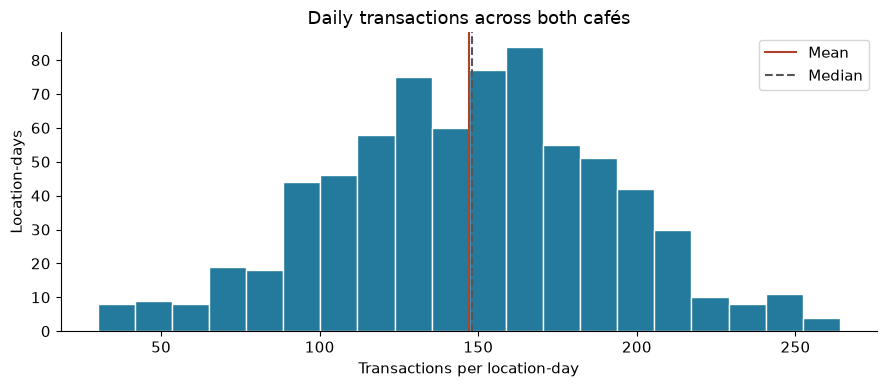

In [14]:
display(clean[['transactions','net_revenue','gross_margin','contribution']].describe().round(2))
fig, ax = plt.subplots()
ax.hist(clean['transactions'], bins=20, color='#247a9c', edgecolor='white')
ax.axvline(clean['transactions'].mean(), color='#ad422d', label='Mean')
ax.axvline(clean['transactions'].median(), color='#555555', linestyle='--', label='Median')
ax.set(title='Daily transactions across both cafés', xlabel='Transactions per location-day', ylabel='Location-days')
ax.legend()
plt.tight_layout()
plt.show()

### Exercise 7 — Explore the distribution of contribution


Create a histogram of daily contribution with mean and median lines, meaningful labels, and dollars on the horizontal axis.
Calculate the 25th and 75th percentiles, their difference (IQR), and the number and percentage of days with contribution below $400.
In 4–6 sentences, describe the shape and spread, decide which center is more informative, and explain why $400 is a management threshold rather than an error rule.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

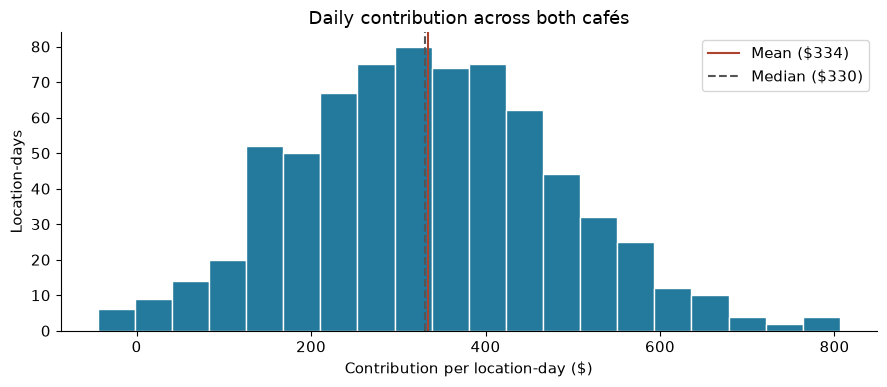

25th percentile (Q1): $228.31
75th percentile (Q3): $432.41
IQR (Q3 − Q1): $204.10
Mean: $334.09
Median: $330.19
Days with contribution < $400: 484 (67.5%)


In [15]:
# Exercise 7: Contribution distribution
fig, ax = plt.subplots()
ax.hist(clean['contribution'], bins=20, color='#247a9c', edgecolor='white')
ax.axvline(clean['contribution'].mean(), color='#ad422d',
           label=f'Mean (${clean["contribution"].mean():.0f})')
ax.axvline(clean['contribution'].median(), color='#555555', linestyle='--',
           label=f'Median (${clean["contribution"].median():.0f})')
ax.set(title='Daily contribution across both cafés',
       xlabel='Contribution per location-day ($)', ylabel='Location-days')
ax.legend()
plt.tight_layout()
plt.show()

q25 = clean['contribution'].quantile(0.25)
q75 = clean['contribution'].quantile(0.75)
iqr = q75 - q25
below_400 = (clean['contribution'] < 400).sum()
below_400_pct = below_400 / len(clean) * 100

print(f"25th percentile (Q1): ${q25:.2f}")
print(f"75th percentile (Q3): ${q75:.2f}")
print(f"IQR (Q3 − Q1): ${iqr:.2f}")
print(f"Mean: ${clean['contribution'].mean():.2f}")
print(f"Median: ${clean['contribution'].median():.2f}")
print(f"Days with contribution < $400: {below_400} ({below_400_pct:.1f}%)")

**Your response:**

The histogram has one main peak with a slight right tail, and contribution ranges from about −$44.60 to $806.18 per location-day. The mean is $334.09 and the median is $330.19, so they give a similar picture of a typical day. The middle half of the values runs from $228.31 to $432.41, giving an IQR of $204.10. I would use the median to describe a typical day because a few high values affect it less than the mean. There are 484 of 717 location-days below $400, or 67.5%. The $400 threshold is a management target for comparison, not evidence that a record is wrong or a proven break-even point.

## Activity 8 — Compare locations fairly · 30 minutes
**Budget:** read 6 min; worked example 6 min; coding 10 min; interpretation 8 min.

Totals measure overall business volume; daily averages help compare locations with different numbers of retained days.
Neither measure is universally better. The right measure depends on the question and what data are available.
`groupby().agg()` calculates several named summaries at once. Here we compute margin from totals,
rather than averaging the daily ratios.

A boxplot shows the median, middle 50% of values, and more extreme observations.
Points beyond the whiskers are unusual by a statistical convention, not automatically mistakes.
Two locations may overlap substantially even when one has a higher average.

In [16]:
location_summary = clean.groupby('location').agg(
    observed_days=('date','size'), total_revenue=('net_revenue','sum'),
    mean_daily_revenue=('net_revenue','mean'), total_gross_profit=('gross_profit','sum'),
    mean_daily_contribution=('contribution','mean'))
location_summary['weighted_gross_margin'] = location_summary['total_gross_profit'] / location_summary['total_revenue']
display(location_summary.round(3))

,observed_days,total_revenue,mean_daily_revenue,total_gross_profit,mean_daily_contribution,weighted_gross_margin
location,,,,,,
Library,363,310859.685,856.363,191902.023,258.473,0.617
Student Center,354,470509.882,1329.124,277167.152,411.635,0.589


### Exercise 8 — Recommend a location for attention


Create side-by-side boxplots of daily contribution for the two locations.
Calculate the dollar and percentage difference between their mean daily revenues,
using Library as the percentage denominator. Compare revenue, contribution, and weighted gross margin.
Write a 5–7-sentence recommendation about which location deserves operational attention;
state one additional piece of information you would request before changing resources.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

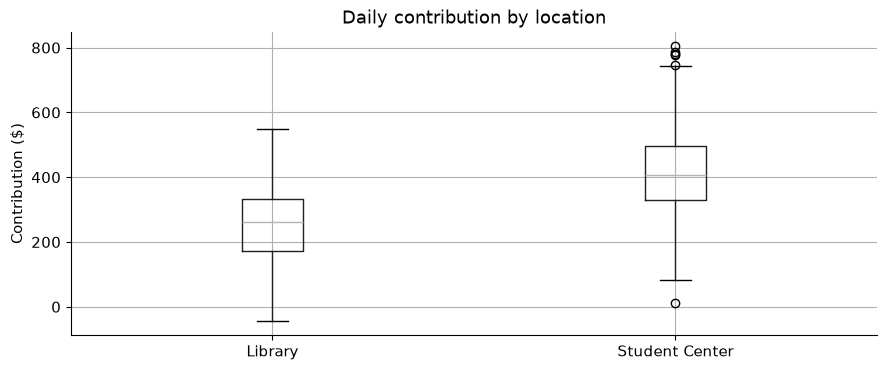

Library mean daily revenue:        $856.36
Student Center mean daily revenue:  $1329.12
Dollar difference (SC − Lib):       $472.76
Percentage difference (vs Library):  55.2%

Library weighted gross margin:       0.617
Student Center weighted gross margin: 0.589

Library mean daily contribution:     $258.47
Student Center mean daily contribution: $411.64


In [17]:
# Exercise 8: Location comparison
fig, ax = plt.subplots()
clean.boxplot(column='contribution', by='location', ax=ax)
ax.set(title='Daily contribution by location', xlabel='', ylabel='Contribution ($)')
plt.suptitle('')
plt.tight_layout()
plt.show()

lib_rev = location_summary.loc['Library', 'mean_daily_revenue']
sc_rev = location_summary.loc['Student Center', 'mean_daily_revenue']
rev_diff = sc_rev - lib_rev
rev_pct = rev_diff / lib_rev * 100

print(f"Library mean daily revenue:        ${lib_rev:.2f}")
print(f"Student Center mean daily revenue:  ${sc_rev:.2f}")
print(f"Dollar difference (SC − Lib):       ${rev_diff:.2f}")
print(f"Percentage difference (vs Library):  {rev_pct:.1f}%")
print(f"\nLibrary weighted gross margin:       {location_summary.loc['Library', 'weighted_gross_margin']:.3f}")
print(f"Student Center weighted gross margin: {location_summary.loc['Student Center', 'weighted_gross_margin']:.3f}")
print(f"\nLibrary mean daily contribution:     ${location_summary.loc['Library', 'mean_daily_contribution']:.2f}")
print(f"Student Center mean daily contribution: ${location_summary.loc['Student Center', 'mean_daily_contribution']:.2f}")

**Your response:**

I would first investigate Library because its mean daily contribution is $258.47, compared with $411.64 at Student Center. Mean daily revenue is $856.36 at Library and $1,329.12 at Student Center, a difference of $472.76 or 55.2% relative to Library. Daily averages are useful here because the locations have different numbers of retained days. Library has the higher weighted gross margin, about 61.7% versus 58.9%, so its lower contribution does not mean that its gross-margin percentage is lower. The boxplots also overlap, showing that Student Center does not have a higher contribution on every day. Before changing resources, I would ask for hourly transactions, queues, and staffing information to understand where the demand and workload differ.

## Activity 9 — Investigate weekday demand · 30 minutes
**Budget:** read 6 min; worked example 6 min; coding 10 min; interpretation 8 min.

Alphabetical weekday order is rarely useful. Put days in calendar order so the pattern is easy to read.
Use average transactions per observed location-day to avoid letting differing weekday counts determine the chart.
Counts still matter: a mean based on fewer observations is less stable and may cover a different mix of dates.

Staffing recommendations require demand, workload, service standards, and employee availability.
This file has daily totals, so it can support a discussion about which **days** deserve attention.
It cannot identify busy hours or prove that cutting employee-hours will preserve customer service.

,mean,median,count
weekday,,,
Monday,151.0,150.0,99
Tuesday,149.8,153.5,102
Wednesday,167.1,163.0,105
Thursday,162.2,161.5,104
Friday,163.3,162.0,103
Saturday,120.3,115.0,101
Sunday,115.5,119.0,103


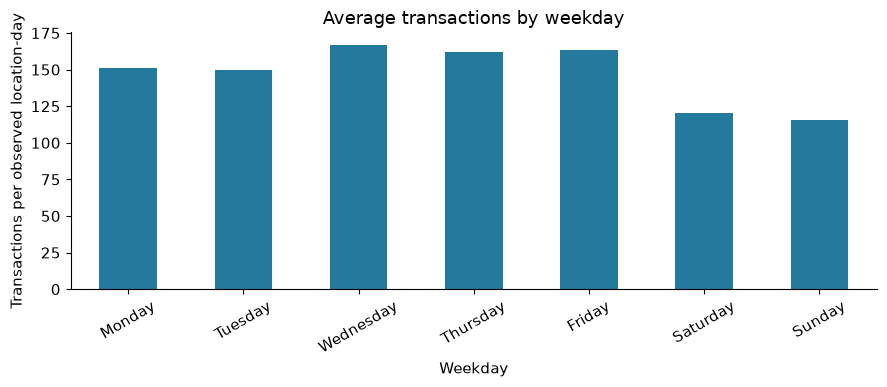

In [18]:
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday_demand = clean.groupby('weekday')['transactions'].agg(['mean','median','count']).reindex(weekday_order)
display(weekday_demand.round(1))
ax = weekday_demand['mean'].plot.bar(color='#247a9c', rot=30)
ax.set(title='Average transactions by weekday', xlabel='Weekday', ylabel='Transactions per observed location-day')
plt.tight_layout(); plt.show()

### Exercise 9 — Separate the locations


Create a weekday-by-location pivot table of average transactions, put weekdays in calendar order,
and plot it as a grouped bar chart. Also calculate transactions per employee-hour for each location
as **total transactions / total staff_hours_used**. Propose which weekday(s) to investigate for staffing changes.
Use two numerical findings and explain why daily data cannot tell you which shifts to change.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

Average transactions by weekday and location:


location,Library,Student Center
weekday,,
Monday,129.2,173.2
Tuesday,123.8,176.8
Wednesday,145.2,189.5
Thursday,137.4,187.1
Friday,141.1,186.0
Saturday,95.7,146.3
Sunday,92.3,139.2


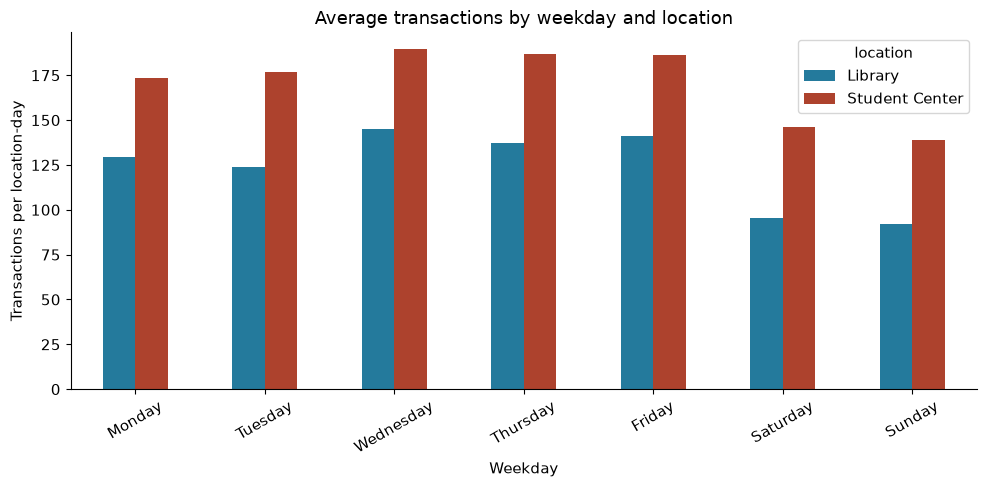


Transactions per employee-hour:
  Library: 44848 transactions / 5172.4 employee-hours = 8.67 txn/emp-hr
  Student Center: 60666 transactions / 6765.1 employee-hours = 8.97 txn/emp-hr


In [19]:
# Exercise 9: Weekday × Location analysis
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

# Pivot table
pivot_wd = clean.pivot_table(values='transactions', index='weekday',
                              columns='location', aggfunc='mean').reindex(weekday_order)
print("Average transactions by weekday and location:")
display(pivot_wd.round(1))

# Grouped bar chart
fig, ax = plt.subplots(figsize=(10, 5))
pivot_wd.plot.bar(ax=ax, color=['#247a9c', '#ad422d'], rot=30)
ax.set(title='Average transactions by weekday and location',
       xlabel='Weekday', ylabel='Transactions per location-day')
plt.tight_layout()
plt.show()

# Transactions per employee-hour
print("\nTransactions per employee-hour:")
for loc in ['Library', 'Student Center']:
    subset = clean.loc[clean['location'] == loc]
    total_txn = subset['transactions'].sum()
    total_sh = subset['staff_hours_used'].sum()
    ratio = total_txn / total_sh
    print(f"  {loc}: {total_txn} transactions / {total_sh:.1f} employee-hours = {ratio:.2f} txn/emp-hr")

**Your response:**

I would investigate weekend scheduling, particularly at Library, where Sunday averages 92.3 transactions compared with 145.2 on Wednesday. Student Center also has fewer transactions on Sunday, averaging 139.2 compared with 189.5 on Wednesday. Transactions per employee-hour are 8.67 at Library and 8.97 at Student Center, calculated using total transactions divided by total staff_hours_used. This ratio does not show all employee work, such as preparation and cleaning. I would collect hourly demand and service information before changing shifts, because daily totals do not show when customers arrive or how many employees are needed at peak times.

## Activity 10 — Explore seasonality and weather · 30 minutes
**Budget:** read 6 min; worked example 6 min; coding 10 min; interpretation 8 min.

A time-series graph puts observations in date order. A seven-day moving average smooths short-term variation,
but it can hide sudden changes. Here we smooth the location-day series separately for each café.
`rolling(7)` means seven **observations**, which may span more than seven calendar days after invalid days are removed.

Seasonal patterns can have competing explanations. Warm months may coincide with summer vacation;
temperature and campus attendance can move in opposite directions. A scatterplot shows an association,
not what would happen if we could change the weather while holding everything else fixed.

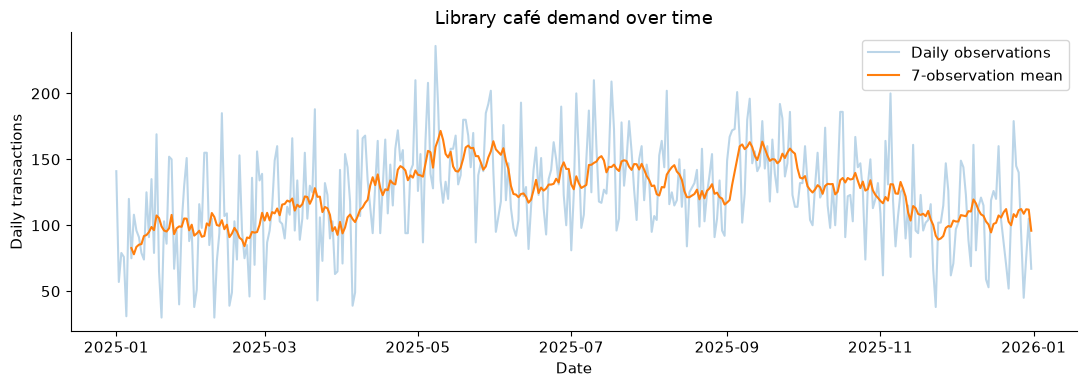

In [20]:
library_series = clean.loc[clean['location'].eq('Library')].set_index('date')['transactions']
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(library_series.index, library_series, alpha=.30, label='Daily observations')
ax.plot(library_series.index, library_series.rolling(7, min_periods=7).mean(), label='7-observation mean')
ax.set(title='Library café demand over time', xlabel='Date', ylabel='Daily transactions')
ax.legend(); plt.tight_layout(); plt.show()

### Exercise 10 — Look for competing explanations


Create (a) a line chart of monthly mean transactions by location and (b) a scatterplot of temperature versus transactions,
using a separate color and legend entry for each location. Use only rows with observed temperature for the scatterplot
and report how many rows you excluded. Calculate the pooled correlation between temperature and transactions.
Identify a pattern and two explanations that these graphs cannot distinguish. Explain why a correlation is not a percent increase.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

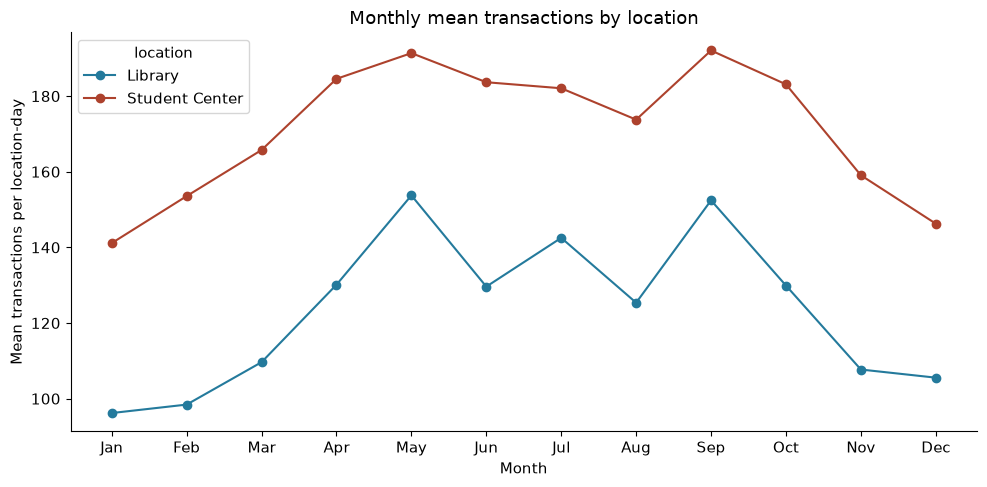

Rows excluded (missing temperature): 18


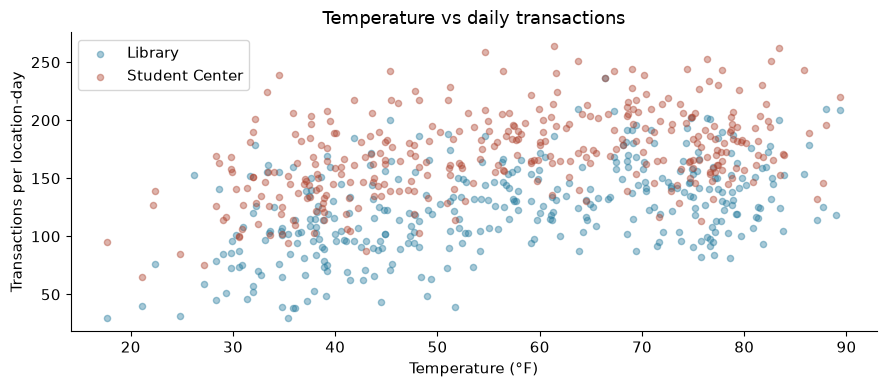

Pooled correlation (temperature vs transactions): 0.395


In [21]:
# Exercise 10: Seasonality and weather

# (a) Monthly mean transactions by location
monthly_means = clean.groupby(['month', 'location'])['transactions'].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 5))
monthly_means.plot(ax=ax, marker='o', color=['#247a9c', '#ad422d'])
ax.set(title='Monthly mean transactions by location',
       xlabel='Month', ylabel='Mean transactions per location-day')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
plt.tight_layout()
plt.show()

# (b) Scatterplot: temperature vs transactions
has_temp = clean.dropna(subset=['temperature_f'])
excluded_count = len(clean) - len(has_temp)
print(f"Rows excluded (missing temperature): {excluded_count}")

fig, ax = plt.subplots()
for loc, color in [('Library', '#247a9c'), ('Student Center', '#ad422d')]:
    subset = has_temp.loc[has_temp['location'] == loc]
    ax.scatter(subset['temperature_f'], subset['transactions'],
               alpha=0.4, s=20, color=color, label=loc)
ax.set(title='Temperature vs daily transactions',
       xlabel='Temperature (°F)', ylabel='Transactions per location-day')
ax.legend()
plt.tight_layout()
plt.show()

# Pooled correlation
corr_pooled = has_temp['temperature_f'].corr(has_temp['transactions'])
print(f"Pooled correlation (temperature vs transactions): {corr_pooled:.3f}")

**Your response:**

The monthly chart shows that Library is highest in May at about 153.7 transactions per day, with September close behind at 152.4. Student Center is highest in September at 192.1, followed by May at 191.4; neither location peaks in June–August. The temperature scatterplot excludes 18 missing-temperature rows and uses 699 observations, with a pooled correlation of 0.395. One possible explanation is that warmer weather is associated with more café visits; another is that the academic calendar and campus attendance change at the same time as temperature. These are possible explanations, and the graphs cannot tell which one accounts for the pattern. A correlation of 0.395 describes the direction and strength of a linear relationship, not a 39.5% increase in transactions.

## Activity 11 — Evaluate discounts and event days · 30 minutes
**Budget:** read 6 min; worked example 6 min; coding 10 min; interpretation 8 min.

A promotion can raise transaction counts while reducing the amount earned from each purchase.
Compare volume, revenue, and contribution together. Use means per observed location-day and include group sizes.
Raw totals are misleading when groups contain different numbers of days.

An observational comparison is not a randomized experiment. Discounts may occur on days with different demand,
weather, or location mix. Looking within a location and event status makes the comparison more specific,
but it does not remove every confounding factor. Avoid saying a discount *caused* a difference based only on these summaries.

,days,mean_transactions,mean_revenue,mean_contribution
discount_rate,,,,
0.0,484,141.08,1096.58,370.53
0.1,150,156.21,1096.81,293.80
0.2,83,166.24,1037.41,194.45


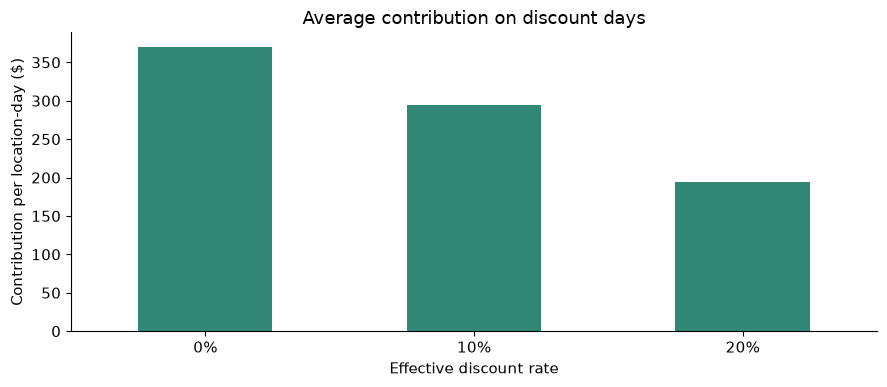

In [22]:
discount_summary = clean.groupby('discount_rate').agg(
    days=('date','size'), mean_transactions=('transactions','mean'),
    mean_revenue=('net_revenue','mean'), mean_contribution=('contribution','mean'))
display(discount_summary.round(2))
ax = discount_summary['mean_contribution'].rename(index=lambda x:f'{x:.0%}').plot.bar(color='#328875',rot=0)
ax.set(title='Average contribution on discount days', xlabel='Effective discount rate', ylabel='Contribution per location-day ($)')
plt.tight_layout(); plt.show()

### Exercise 11 — Check the comparison groups


Build a table grouped by location, campus_event, and discount_rate with group size, mean transactions,
mean net revenue, and mean contribution. Within **Library, non-event days**, compare 20% discount days with 0% days:
calculate the percentage differences in mean transactions and contribution, using 0% days as the denominator.
Then compare event versus non-event mean transactions within each location.
Write 5–7 sentences about whether to continue discounts and describe a better-designed test.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [23]:
# Exercise 11: Compare discounts and event days
# Grouped table
detail = clean.groupby(['location', 'campus_event', 'discount_rate']).agg(
    days=('date', 'size'),
    mean_transactions=('transactions', 'mean'),
    mean_revenue=('net_revenue', 'mean'),
    mean_contribution=('contribution', 'mean')
).round(2)
display(detail)

# Library, non-event: 20% vs 0%
lib_no_ev = clean.loc[(clean['location'] == 'Library') & (clean['campus_event'] == 0)]
lib_0 = lib_no_ev.loc[lib_no_ev['discount_rate'] == 0]
lib_20 = lib_no_ev.loc[lib_no_ev['discount_rate'] == 0.20]

print(f"\n=== Library, non-event days ===")
print(f"0% discount: n={len(lib_0)}, mean_txn={lib_0['transactions'].mean():.1f}, mean_contrib=${lib_0['contribution'].mean():.2f}")
print(f"20% discount: n={len(lib_20)}, mean_txn={lib_20['transactions'].mean():.1f}, mean_contrib=${lib_20['contribution'].mean():.2f}")

txn_pct = (lib_20['transactions'].mean() - lib_0['transactions'].mean()) / lib_0['transactions'].mean() * 100
contrib_pct = (lib_20['contribution'].mean() - lib_0['contribution'].mean()) / lib_0['contribution'].mean() * 100
print(f"Transaction change (20% vs 0%): {txn_pct:+.1f}%")
print(f"Contribution change (20% vs 0%): {contrib_pct:+.1f}%")

# Event vs non-event within each location
print(f"\n=== Event vs non-event comparison ===")
for loc in ['Library', 'Student Center']:
    subset = clean.loc[clean['location'] == loc]
    ev = subset.loc[subset['campus_event'] == 1, 'transactions'].mean()
    nev = subset.loc[subset['campus_event'] == 0, 'transactions'].mean()
    n_ev = int((subset['campus_event'] == 1).sum())
    n_nev = int((subset['campus_event'] == 0).sum())
    print(f"{loc}: event days mean_txn={ev:.1f} (n={n_ev}), non-event mean_txn={nev:.1f} (n={n_nev})")

days  mean_transactions  \
location       campus_event discount_rate                            
Library        0            0.0             233             113.73   
                            0.1              59             121.95   
                            0.2              36             145.56   
               1            0.0              21             172.62   
                            0.1               9             161.00   
                            0.2               5             168.00   
Student Center 0            0.0             205             160.14   
                            0.1              76             176.13   
                            0.2              38             178.58   
               1            0.0              25             213.32   
                            0.1               6             233.50   
                            0.2               4             233.00   

                                           mean_revenue  mean_contribution  
location       campus_event discount_rate                                   
Library        0            0.0                  827.01             271.56  
                            0.1                  800.14             210.67  
                            0.2                  853.05             162.40  
               1            0.0                 1248.16             428.73  
                            0.1                 1002.24             255.77  
                            0.2                 1003.48             194.31  
Student Center 0            0.0                 1311.77             449.60  
                            0.1                 1289.35             346.90  
                            0.2                 1165.64             216.06  
               1            0.0                 1717.08             595.64  
                            0.1                 1716.98             495.74  
                            0.2                 1520.82             277.75


=== Library, non-event days ===
0% discount: n=233, mean_txn=113.7, mean_contrib=$271.56
20% discount: n=36, mean_txn=145.6, mean_contrib=$162.40
Transaction change (20% vs 0%): +28.0%
Contribution change (20% vs 0%): -40.2%

=== Event vs non-event comparison ===
Library: event days mean_txn=169.0 (n=35), non-event mean_txn=118.7 (n=328)
Student Center: event days mean_txn=219.0 (n=35), non-event mean_txn=166.1 (n=319)


**Your response:**

I would test the 20% discount before continuing it routinely at Library on non-event days. The 36 discounted days average 145.6 transactions versus 113.7 on the 233 no-discount days, a 28.0% difference. However, their mean contribution is $162.40 versus $271.56, or 40.2% lower. Event-day transactions are also higher than non-event transactions at both cafés: 169.0 versus 118.7 at Library, and 219.0 versus 166.1 at Student Center. These comparisons do not prove that discounts or events caused the differences, because the groups may contain different weekdays or seasons. A better test would randomly assign eligible Library non-event days to 20% or no discount within weekday groups, then compare mean daily contribution while also checking transactions and wait times.

## Activity 12 — Turn exploration into a recommendation · 30 minutes
**Budget:** read 4 min; plan 4 min; figure/evidence 10 min; recommendation 12 min.

The manager needs a decision, evidence, and limits. Choose charts that answer specific questions and label their units.
A chart title such as “Average daily contribution by discount rate” is more informative than “Bar chart.”
Show bars from zero when comparing magnitudes; avoid making small differences look dramatic through a truncated axis.
Keep the same units when comparing groups. Rounding for display is useful, but do not round inputs before calculating.

Your recommendation must separate what you observed from what you propose. If evidence is mixed,
recommend a small test or additional data collection and define how success would be judged.
Do not claim savings from an untested staffing reduction, or imply the café's true net profit is known.

### Exercise 12 — Brief the café manager


Create **one presentation-ready chart of your choice** that supports a decision from Activities 7–11.
Add a compact evidence table with at least three findings (measure, value, unit/group).
Then write **250–350 words** with: (1) three concrete recommendations; (2) at least four numerical findings;
(3) two limitations, including one data-preparation issue; and (4) one proposed follow-up test and its success metric.
State which recommendation you would prioritize and why. Use evidence already computed rather than introducing regression early.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

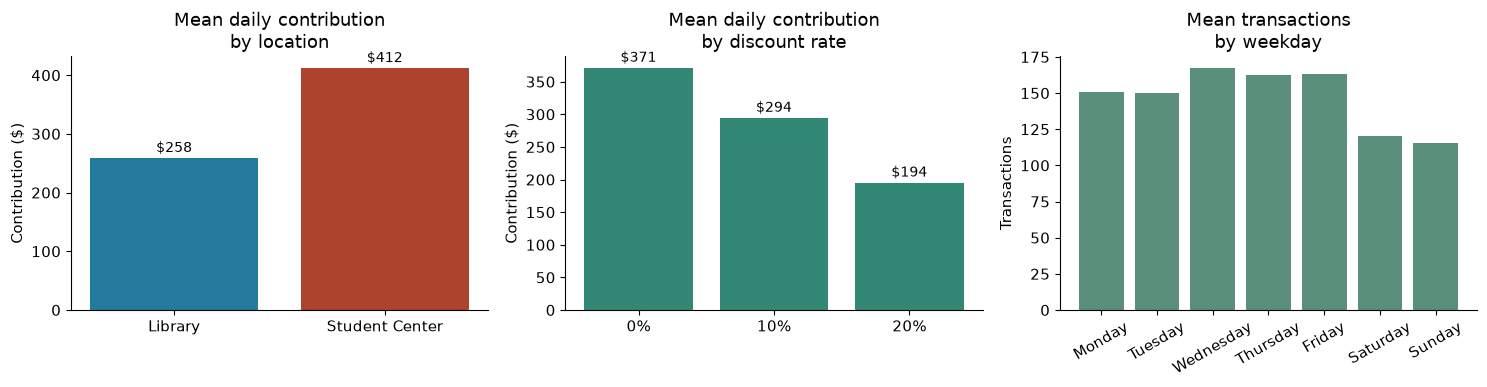

,Finding,Value,Unit/group
0,Student Center minus Library contribution,$153.16,Mean dollars per observed location-day
1,Library contribution: 20% versus no discount,-40.20%,Library non-event days; no-discount denominator
2,Library transactions: event versus non-event,+42.35%,Library; non-event denominator
3,Transactions: weekend versus weekday,-25.78%,Both locations; weekday denominator


In [24]:
# Exercise 12: Manager briefing — chart and evidence table

# Multi-panel chart for the manager
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Panel 1: Contribution by location
locs = ['Library', 'Student Center']
contribs = [clean.loc[clean['location']==l, 'contribution'].mean() for l in locs]
bars1 = axes[0].bar(locs, contribs, color=['#247a9c', '#ad422d'])
axes[0].set(title='Mean daily contribution\nby location', ylabel='Contribution ($)', ylim=(0, None))
for bar, val in zip(bars1, contribs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'${val:.0f}', ha='center', va='bottom', fontsize=10)

# Panel 2: Contribution by discount rate
rates = [0, 0.10, 0.20]
contribs_disc = [clean.loc[clean['discount_rate']==r, 'contribution'].mean() for r in rates]
bars2 = axes[1].bar(['0%', '10%', '20%'], contribs_disc, color='#328875')
axes[1].set(title='Mean daily contribution\nby discount rate', ylabel='Contribution ($)', ylim=(0, None))
for bar, val in zip(bars2, contribs_disc):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'${val:.0f}', ha='center', va='bottom', fontsize=10)

# Panel 3: Weekday transactions
wd_mean = clean.groupby('weekday')['transactions'].mean().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
bars3 = axes[2].bar(wd_mean.index, wd_mean.values, color='#5a8f7b')
axes[2].set(title='Mean transactions\nby weekday', ylabel='Transactions')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# Evidence table: calculate each finding from the retained observations.
event_means = clean.groupby(['location', 'campus_event'])['transactions'].mean()
weekend_mean = clean.loc[clean['is_weekend'], 'transactions'].mean()
weekday_mean = clean.loc[~clean['is_weekend'], 'transactions'].mean()
contribution_gap = (location_summary.loc['Student Center', 'mean_daily_contribution']
                    - location_summary.loc['Library', 'mean_daily_contribution'])
library_event_pct = 100 * (event_means.loc[('Library', 1)] / event_means.loc[('Library', 0)] - 1)
weekend_pct = 100 * (weekend_mean / weekday_mean - 1)
evidence = pd.DataFrame({
    'Finding': ['Student Center minus Library contribution',
                'Library contribution: 20% versus no discount',
                'Library transactions: event versus non-event',
                'Transactions: weekend versus weekday'],
    'Value': [f'${contribution_gap:.2f}', f'{contrib_pct:+.2f}%',
              f'{library_event_pct:+.2f}%', f'{weekend_pct:+.2f}%'],
    'Unit/group': ['Mean dollars per observed location-day',
                   'Library non-event days; no-discount denominator',
                   'Library; non-event denominator',
                   'Both locations; weekday denominator']
})
display(evidence)


**Your response:**

My first recommendation is to test the 20% discount at Library before using it routinely. On non-event days, the discounted group averages 145.6 transactions, compared with 113.7 without a discount. However, its average contribution is only $162.40, compared with $271.56. This is 28.0% more transactions but 40.2% less contribution. I would make this the priority because more sales do not necessarily mean more money left after the costs included in this exercise. The difference is a reason to run a test, rather than a guarantee that removing discounts would add $109 per day.

Second, I would review staffing and preparation on event days. Library averages 169.0 transactions on event days and 118.7 otherwise. Student Center averages 219.0 versus 166.1. Before adding employees, I would check hourly orders, queues, and current shifts to see when extra help might be needed.

Third, I would investigate weekend scheduling at Library. Saturday and Sunday average about 95.7 and 92.3 transactions, compared with 145.2 on Wednesday. This suggests checking whether the schedule matches demand, but daily totals cannot tell us which shifts to change or how much money could safely be saved.

There are two main limitations. Fourteen staffing values were filled using location medians, so some contribution values depend on estimated labor costs. Also, discount days were not randomly selected, so weekday or seasonal differences may affect the comparison.

For a follow-up, I would randomly assign Library non-event days to 20% or no discount within weekday groups. The main success measure would be higher mean contribution in the no-discount group during the same trial, while checking that wait times remain within a service target agreed before the trial.

# Part 3 — Linear regression · 60 minutes
## Activity 13 — Define a prediction question and split the data · 15 minutes
**Budget:** read 5 min; worked example 5 min; exercise/write 5 min.

**Question:** can daily temperature help predict the number of transactions at a café on a future day?
We will fit **simple linear regression**: `predicted transactions = intercept + slope × temperature`.
The slope is the change in predicted transaction count for a one-degree Fahrenheit increase.
The intercept is the prediction at 0°F, which may be far outside our observed range and have little business meaning.

Training data teach the model its coefficients. Test data assess predictions on observations the model did not see.
Because the goal is a future-day prediction, we reserve November–December as the test period and train on January–October.
Both cafés on a given date stay on the same side of the cutoff. A random row split could mix the same day's shared weather
across training and test data and would not mimic this future-period question.

Actual daily average temperature is known after the day; a real advance forecast would use forecast temperature,
which introduces additional error. This is a simplified retrospective exercise. Location, events, weekdays, and seasonality
are omitted deliberately so we can learn a one-predictor model.

In [25]:
train = clean.loc[clean['date'] < '2025-11-01'].copy()
test = clean.loc[clean['date'] >= '2025-11-01'].copy()
# Learn the imputation value from TRAINING observations only.
training_temp_median = train['temperature_f'].median()
X_train = train[['temperature_f']].fillna(training_temp_median)
X_test = test[['temperature_f']].fillna(training_temp_median)
y_train = train['transactions']
y_test = test['transactions']
print('Training rows:', len(train), 'Test rows:', len(test))
print('Temperature fill value learned from training:', round(training_temp_median,1))
assert train['date'].max() < test['date'].min()
assert not set(train['date']).intersection(set(test['date']))

Training rows: 596 Test rows: 121
Temperature fill value learned from training: 61.6


### Exercise 13 — Check what the model can know


Print the first/last date and observed temperature minimum/maximum for each split, plus the number of imputed temperatures.
Identify the predictor and target. Explain why using a median from the entire dataset would leak test information,
why net revenue would be a poor input for an advance transaction forecast, and one risk of evaluating only November–December.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [26]:
# Exercise 13: Check the data split
print("=== Training set ===")
print(f"Date range: {train['date'].min().date()} to {train['date'].max().date()}")
print(f"Temperature range (observed): {train['temperature_f'].min():.1f}°F to {train['temperature_f'].max():.1f}°F")
print(f"Missing temperatures (to be imputed): {train['temperature_f'].isna().sum()}")

print("\n=== Test set ===")
print(f"Date range: {test['date'].min().date()} to {test['date'].max().date()}")
print(f"Temperature range (observed): {test['temperature_f'].min():.1f}°F to {test['temperature_f'].max():.1f}°F")
print(f"Missing temperatures (to be imputed): {test['temperature_f'].isna().sum()}")

print(f"\nPredictor (X): temperature_f")
print(f"Target (y): transactions")

=== Training set ===
Date range: 2025-01-01 to 2025-10-31
Temperature range (observed): 17.7°F to 89.4°F
Missing temperatures (to be imputed): 16

=== Test set ===
Date range: 2025-11-01 to 2025-12-31
Temperature range (observed): 22.4°F to 56.5°F
Missing temperatures (to be imputed): 2

Predictor (X): temperature_f
Target (y): transactions


**Your response:**

The predictor is temperature_f in degrees Fahrenheit, and the target is transactions per location-day. Training covers January 1–October 31 with 596 rows and observed temperatures from 17.7°F to 89.4°F; testing covers November 1–December 31 with 121 rows and temperatures from 22.4°F to 56.5°F. There are 16 missing training temperatures and two missing test temperatures, filled using the training median of 61.6°F. Using the whole dataset's median would let the test period influence the preparation of the model's inputs. Net revenue is a poor advance predictor because it depends on the day's transactions and is not known before trading. A winter-only test also does not show whether the model works well in summer or other academic-calendar periods.

## Activity 14 — Fit and interpret the line · 15 minutes
**Budget:** read 4 min; fit/plot 5 min; exercise/write 6 min.

Linear regression chooses an intercept and slope to minimize the sum of squared training errors.
Squaring makes large misses more influential. Scikit-learn expects predictors as a two-dimensional table;
that is why `[['temperature_f']]` has double brackets, while the target is a single column.

`fit()` learns coefficients. `predict()` applies them. The line summarizes a pooled association across both cafés;
it does not prove that temperature changes cause transaction changes. A straight line may miss curved relationships,
different location baselines, and calendar effects. Only predict within plausible observed ranges for this exercise.

Predicted transactions = 93.07 + 0.96 × temperature_f


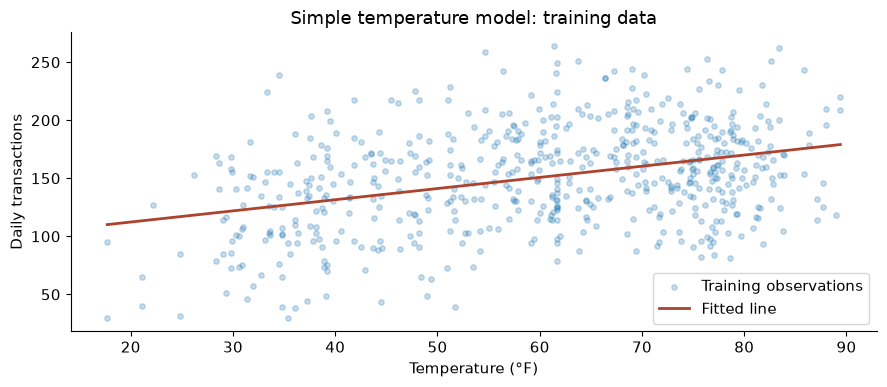

In [27]:
model = LinearRegression()
model.fit(X_train, y_train)
slope = float(model.coef_[0])
intercept = float(model.intercept_)
print(f'Predicted transactions = {intercept:.2f} + {slope:.2f} × temperature_f')
grid = pd.DataFrame({'temperature_f':np.linspace(X_train['temperature_f'].min(), X_train['temperature_f'].max(),100)})
fig, ax = plt.subplots()
ax.scatter(X_train['temperature_f'], y_train, alpha=.25, s=15, label='Training observations')
ax.plot(grid['temperature_f'], model.predict(grid), color='#ad422d', linewidth=2, label='Fitted line')
ax.set(title='Simple temperature model: training data', xlabel='Temperature (°F)', ylabel='Daily transactions')
ax.legend(); plt.tight_layout(); plt.show()

### Exercise 14 — Interpret a prediction


Use `model.predict()` to predict transactions at 40°F, 55°F, and 70°F (a DataFrame with the same predictor name).
Calculate the model's predicted difference between 55°F and 70°F. Interpret the slope with units and explain why
the model's prediction for a specific café-day can differ substantially from the line.
Would the intercept be useful for scheduling? Check the observed range before answering.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [28]:
# Exercise 14: Interpret predictions
temps_to_predict = pd.DataFrame({'temperature_f': [40, 55, 70]})
predicted_values = model.predict(temps_to_predict)

print("Predicted transactions at specific temperatures:")
for temp, pred in zip([40, 55, 70], predicted_values):
    print(f"  At {temp}°F: {pred:.1f} transactions")

diff_55_70 = predicted_values[2] - predicted_values[1]
print(f"\nPredicted difference (70°F − 55°F): {diff_55_70:.1f} transactions")

print(f"\nSlope = {slope:.2f} transactions per °F")
print(f"Intercept = {intercept:.2f} transactions (at 0°F)")
print(f"Training temperature range: {X_train['temperature_f'].min():.1f}°F to {X_train['temperature_f'].max():.1f}°F")

Predicted transactions at specific temperatures:
  At 40°F: 131.5 transactions
  At 55°F: 146.0 transactions
  At 70°F: 160.4 transactions

Predicted difference (70°F − 55°F): 14.4 transactions

Slope = 0.96 transactions per °F
Intercept = 93.07 transactions (at 0°F)
Training temperature range: 17.7°F to 89.4°F


**Your response:**

The model predicts 131.5 transactions at 40°F, 146.0 at 55°F, and 160.4 at 70°F. The predicted increase from 55°F to 70°F is 14.4 transactions. The slope is about 0.96 transactions per location-day for each 1°F increase, describing the fitted relationship rather than a proven weather effect. A particular day can be far from the line because location, events, weekdays, and discounts are left out of this model. I would not use the intercept of 93.07 for scheduling at 0°F because the observed training temperatures only range from 17.7°F to 89.4°F, so that prediction would be outside the data range.

## Activity 15 — Evaluate against a baseline · 15 minutes
**Budget:** read 4 min; run metrics 4 min; exercise/write 7 min.

A prediction model must compete with a simple alternative. Our baseline predicts the training-period mean transactions
for every test row. It uses no temperature information and no test targets to set its prediction.

**Mean absolute error (MAE)** is the average size of a miss, ignoring direction. An MAE of 25 would mean a typical
absolute error of 25 transactions per location-day. Smaller is better.
**R²** compares squared prediction errors with predicting the mean of the evaluation targets. On held-out data,
R² can be negative. It is not prediction accuracy and should not be reported as a percentage of correct forecasts.
The test-mean reference implicit in R² differs from our deployable training-mean baseline, so report both explicitly.

A residual is `actual − predicted`. Positive means the model underpredicted. Residual patterns suggest missing structure;
they are not automatically data errors. We inspect the held-out period once and propose next steps rather than repeatedly tuning to it.

In [29]:
predictions = model.predict(X_test)
baseline_predictions = np.full(len(test), y_train.mean())
model_mae = mean_absolute_error(y_test, predictions)
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
scores = pd.DataFrame({
    'method':['Temperature regression','Training-mean baseline'],
    'test_MAE_transactions':[model_mae,baseline_mae],
    'test_R2':[r2_score(y_test,predictions),r2_score(y_test,baseline_predictions)]})
display(scores.round(3))
evaluation = test[['date','location','transactions','temperature_f']].copy()
evaluation['predicted'] = predictions
evaluation['residual'] = evaluation['transactions'] - evaluation['predicted']
evaluation['absolute_error'] = evaluation['residual'].abs()

,method,test_MAE_transactions,test_R2
0,Temperature regression,32.523,0.047
1,Training-mean baseline,37.393,-0.275


### Exercise 15 — Diagnose the misses


Calculate MAE by location. Draw a residual-versus-predicted scatterplot with separate location colors and a horizontal zero line.
Compute the regression's percentage MAE improvement over the baseline: `100 × (baseline_MAE − model_MAE) / baseline_MAE`.
A negative result means worse performance. Explain the sign of residuals and whether the model improves on the baseline.
Identify one pattern that suggests a missing predictor.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

=== MAE by location ===
  Library: MAE = 35.26 transactions (n=61)
  Student Center: MAE = 29.74 transactions (n=60)


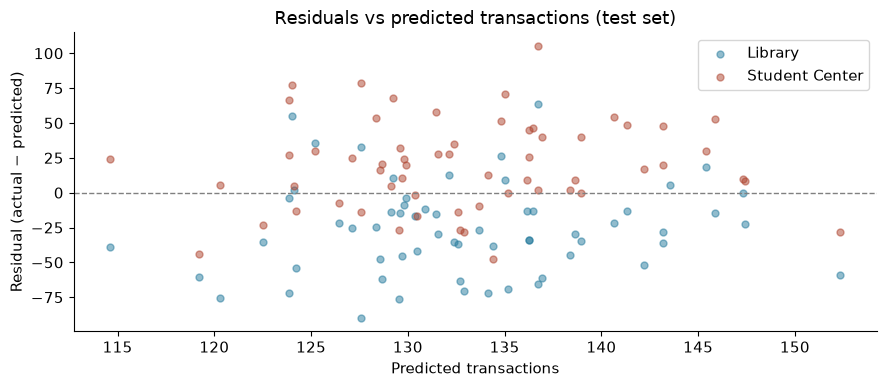


Baseline MAE: 37.39
Model MAE:    32.52
MAE improvement: 13.0%


In [30]:
# Exercise 15: Diagnose misses
# MAE by location
print("=== MAE by location ===")
for loc in ['Library', 'Student Center']:
    subset = evaluation.loc[evaluation['location'] == loc]
    mae_loc = subset['absolute_error'].mean()
    print(f"  {loc}: MAE = {mae_loc:.2f} transactions (n={len(subset)})")

# Residual plot
fig, ax = plt.subplots()
for loc, color in [('Library', '#247a9c'), ('Student Center', '#ad422d')]:
    subset = evaluation.loc[evaluation['location'] == loc]
    ax.scatter(subset['predicted'], subset['residual'],
               alpha=0.5, s=25, color=color, label=loc)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set(title='Residuals vs predicted transactions (test set)',
       xlabel='Predicted transactions', ylabel='Residual (actual − predicted)')
ax.legend()
plt.tight_layout()
plt.show()

# Percentage improvement
improvement_pct = 100 * (baseline_mae - model_mae) / baseline_mae
print(f"\nBaseline MAE: {baseline_mae:.2f}")
print(f"Model MAE:    {model_mae:.2f}")
print(f"MAE improvement: {improvement_pct:.1f}%")

**Your response:**

Test MAE is 35.26 transactions at Library and 29.74 at Student Center. Overall MAE is 32.52, compared with 37.39 for the training-mean baseline, so the model improves MAE by 13.0%. A positive residual means actual demand was higher than predicted, while a negative residual means the model predicted too many transactions. Library residuals tend to be below zero and Student Center residuals tend to be above zero, although there are exceptions at both locations. This suggests investigating location as another predictor, because the model currently makes the same prediction for both cafés at the same temperature. The model improves on the baseline, but its average error still exceeds the manager's tolerance.

## Activity 16 — Decide whether the model is useful · 15 minutes
**Budget:** read 3 min; decision table 4 min; write/review 8 min.

Model usefulness depends on the decision. A demand error might be tolerable for a rough weekly estimate but too large
for a tight daily staffing plan. For this exercise only, the manager's **hypothetical tolerance** is MAE no greater than
25 transactions per location-day, together with improvement over the baseline. This threshold is a stated business assumption,
not a universal standard or a guarantee about individual errors.

A small average error does not ensure fairness across locations or protection against very large misses.
We have only one year, two locations, and a short test period. Synthetic data are suitable for practice but do not validate a real café model.
A full regression course would also examine functional form, dependence over time, unequal error spread, and uncertainty.
We will not estimate causal effects, confidence intervals, or statistical significance in this introductory hour.

### Exercise 16 — Write the model handoff


Create a one-row decision table showing model MAE, baseline MAE, test R², MAE improvement percentage,
whether the model beats the baseline, and whether it meets the 25-transaction tolerance.
Write **120–180 words** recommending use, limited use, or further development.
Include the prediction equation in words, the numerical evaluation, a location-specific concern,
the difference between observed and forecast temperature, and one next predictor to investigate.
Do not refit on the test data. Finish by checking all TODOs and responses before submitting.


Complete the `TODO` cell below, then write your interpretation in the response cell. The starter cells are valid Python; they deliberately leave the exercise work for you.

In [31]:
# Exercise 16: Model handoff decision table
decision_table = pd.DataFrame({
    'Model MAE': [round(model_mae, 2)],
    'Baseline MAE': [round(baseline_mae, 2)],
    'Test R²': [round(r2_score(y_test, predictions), 3)],
    'MAE improvement (%)': [round(improvement_pct, 1)],
    'Beats baseline': [model_mae < baseline_mae],
    'Meets ≤25 MAE tolerance': [model_mae <= 25]
})
display(decision_table)

print(f"\nModel equation: predicted transactions = {intercept:.2f} + {slope:.2f} × temperature_f")
print(f"Test R²: {r2_score(y_test, predictions):.3f}")
print(f"Library test MAE: {evaluation.loc[evaluation['location']=='Library','absolute_error'].mean():.2f}")
print(f"Student Center test MAE: {evaluation.loc[evaluation['location']=='Student Center','absolute_error'].mean():.2f}")

,Model MAE,Baseline MAE,Test R²,MAE improvement (%),Beats baseline,Meets ≤25 MAE tolerance
0,32.52,37.39,0.047,13.0,True,False



Model equation: predicted transactions = 93.07 + 0.96 × temperature_f
Test R²: 0.047
Library test MAE: 35.26
Student Center test MAE: 29.74


**Your response:**

I recommend further development before using this model for daily staffing. In words, predicted transactions equal 93.07 plus about 0.96 times temperature in degrees Fahrenheit. Test MAE is 32.52 transactions, compared with 37.39 for the training-mean baseline, an improvement of 13.0%. Test R² is 0.047; this is not a percentage of correct predictions. The model beats the baseline but does not meet the manager's maximum MAE of 25 transactions.

Library's MAE is 35.26, compared with 29.74 at Student Center, so the errors are not equally large at both cafés. The model uses observed daily temperature, which is only known after the day ends. An advance forecast would use predicted temperature and introduce another source of error. I would investigate location as the next predictor. I would use an earlier validation period within the training data to develop that model, then assess it on a new future holdout rather than repeatedly using this test period.

## Submission checklist

- [ ] Exercises 1–16 contain your code and written interpretations; no TODO is left unanswered.
- [ ] Cleaning choices and the row-count ledger are documented; the clean CSV is exported.
- [ ] Charts have informative titles, units, readable labels, and legends where needed.
- [ ] Comparisons use appropriate denominators and include sample sizes or coverage where relevant.
- [ ] The 250–350-word recommendation cites four numerical findings and two limitations.
- [ ] Regression uses the chronological split, training-only imputation, baseline, MAE, R², and residuals.
- [ ] The 120–180-word model handoff reports whether both decision criteria are met.
- [ ] After saving your work, **Restart Kernel → Run All** completes without errors and saves visible outputs.

### Optional extensions — outside the six-hour estimate

1. Repeat the contribution comparisons using only observed staffing values. Does the recommendation change?
2. Compare a location-specific training-mean baseline with the pooled baseline. Do not assume temperature adds value.
3. Plan a multiple-regression model with location and weekday. Explain which variables are known before trading,
   how to encode categories, and how you would create a validation period before using a new holdout.

### Instructor timing note

The six-hour allocation is a teaching estimate for students with the stated prerequisites, not a guarantee of individual pace.
Activities can be delivered in three meetings of two hours: preparation; EDA 7–10; EDA 11–12 plus regression 13–16.
Software setup and breaks are additional. The separate instructor notebook includes completed exercise code and grading guidance.

## Assistance disclosure

An AI assistant helped check the calculations, revise the code and explanations, and simplify the English in this notebook.